In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
# intial conditons 

n=5000
# set r
R_max = 10 #A
dr=R_max/(n+1)
# grid 
r = np.linspace(dr, R_max-dr, n)

In [6]:
# define potential
m=940e6 #Mev/c^2
d=0.755501 #eV
a=1.44 # a is alpha 
r0=0.131349 #A angsstrom
rp= ((r-r0)/r)
hbar_c=1973 #MeV.fm
h_bar= 1973

V = np.diag(d * (np.exp(-2*a*rp) - np.exp(-a*rp)))  # np.diag() make array to matix

# angular mometum term
l= 0 # angular momentum
D=np.diag(((h_bar**2)*l*(l+1))/(2*m*(r**2)))

In [7]:
# buliding H matrix

A=np.zeros((n,n))
h_bar= 197.3
C = -1 * ((h_bar**2) / (2 * m * (dr**2)))
for i in range(n):
    for j in range(n):
        if i==j:
            A[i,j]=-2
        elif abs(i-j)== 1:
            A[i,j]=1       
H=A*C

In [8]:
# final matix say F
F = H + V + D 
print(F)

[[ 6.13007447e+80 -5.17857214e+00  0.00000000e+00 ...  0.00000000e+00
   0.00000000e+00  0.00000000e+00]
 [-5.17857214e+00  5.09878082e+39 -5.17857214e+00 ...  0.00000000e+00
   0.00000000e+00  0.00000000e+00]
 [ 0.00000000e+00 -5.17857214e+00  1.03307822e+26 ...  0.00000000e+00
   0.00000000e+00  0.00000000e+00]
 ...
 [ 0.00000000e+00  0.00000000e+00  0.00000000e+00 ...  1.02187711e+01
  -5.17857214e+00  0.00000000e+00]
 [ 0.00000000e+00  0.00000000e+00  0.00000000e+00 ... -5.17857214e+00
   1.02187714e+01 -5.17857214e+00]
 [ 0.00000000e+00  0.00000000e+00  0.00000000e+00 ...  0.00000000e+00
  -5.17857214e+00  1.02187718e+01]]


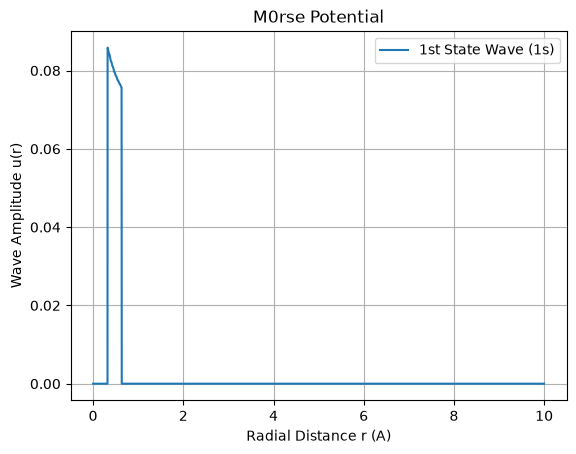

-0.1831585922144218 eV


In [15]:
# find egien value of matrix
energies, wavefunctions = np.linalg.eigh(F)

#sloution
u_0 = -wavefunctions[:, 1]

#plot
plt.plot(r, u_0, label="1st State Wave (1s)")
#plt.xlim(0,0.04)
plt.title("M0rse Potential")
plt.xlabel("Radial Distance r (A)")
plt.ylabel("Wave Amplitude u(r)")
plt.legend()
plt.grid(True)
plt.show()
print(energies[0],"eV")